In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [ ]:
data = {
    'Hours' : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Score' : [35, 40, 50, 55, 65, 70, 75, 85, 90, 95 ]
}

df = pd.DataFrame(data)

df

,Hours,Score
0,1,35
1,2,40
2,3,50
3,4,55
4,5,65
5,6,70
6,7,75
7,8,85
8,9,90
9,10,95


In [ ]:
df.describe()

,Hours,Score
count,10.00000,10.000000
mean,5.50000,66.000000
std,3.02765,20.789955
min,1.00000,35.000000
25%,3.25000,51.250000
50%,5.50000,67.500000
75%,7.75000,82.500000
max,10.00000,95.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Hours   10 non-null     int64
 1   Score   10 non-null     int64
dtypes: int64(2)
memory usage: 292.0 bytes


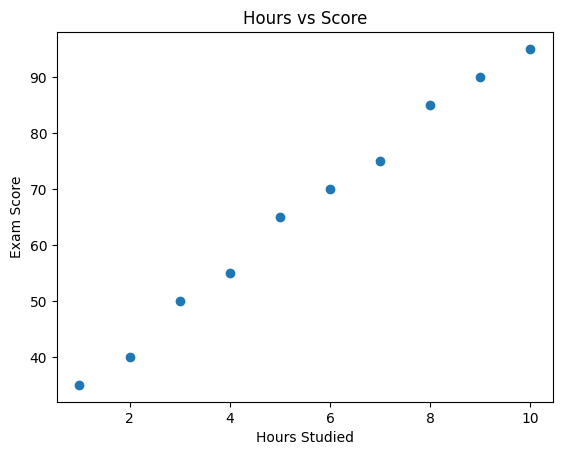

In [ ]:
plt.scatter (df['Hours'], df['Score'])

plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')
plt.title('Hours vs Score')
plt.show()

#positive relation

In [ ]:
#scikit works on more than 1 independent variable

X = df[['Hours']] #feature variables should be 2D array for scikit learn
y = df['Score']

print('Feature:')
print(X)

print('Target:')
print(y)

Feature:
   Hours
0      1
1      2
2      3
3      4
4      5
5      6
6      7
7      8
8      9
9     10
Target:
0    35
1    40
2    50
3    55
4    65
5    70
6    75
7    85
8    90
9    95
Name: Score, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
X,
y,
test_size=0.3,
random_state=42
)

print('Training Samples: ', len(X_train))
print('Testing Samples: ', len(X_test))

Training Samples:  7
Testing Samples:  3


In [ ]:
#gives error why?

# model = LinearRegression()

# model.fit(X_train, y_train)

In [ ]:
model = LinearRegression()

model.fit(X_train.values.reshape(-1,1), y_train) #values (hours) extracted (which are 1D) and reshaped (into 2D -> (1,1), (2,1), (3,1).. -1 replaced)



LinearRegression()

In [ ]:
#MODEL PARAMETERS :

print("Coefficient: ", model.coef_[0]) #slope
print("Intercept: ", model.intercept_)

Coefficient:  6.72029702970297
Intercept:  29.232673267326724


In [ ]:
#GENERATE PREDICTIONS :

y_pred = model.predict(X_test.values.reshape(-1,1))

print("predicted value:" )
print(y_pred)

predicted value:
[89.71534653 42.67326733 69.55445545]


In [ ]:
#COMPARISON :

comparison = pd.DataFrame({
    'Actual Score': y_test,
    'Predicted Score': y_pred
})

print(comparison)

   Actual Score  Predicted Score
8            90        89.715347
1            40        42.673267
5            70        69.554455


In [ ]:
#EVALUATION METRICS

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error: ", mae)
print("Mean Squared Error: ", mse)
print("Root Mean Squared Error: ", rmse)
print("R-squared: ", r2)


Mean Absolute Error:  1.134488448844884
Mean Squared Error:  2.475298581838366
Root Mean Squared Error:  1.5733081649309413
R-squared:  0.9941374507272249


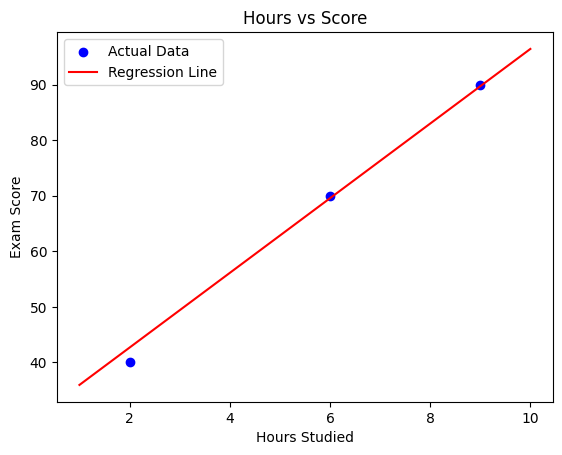

In [ ]:
#REGRESSION LINE

plt.scatter(
    X_test,
    y_test,
    label = 'Actual Data',
    color = 'blue'
  )

plt.plot(
    X,
    model.predict(X.values.reshape(-1,1)),
    color = 'red',
    label = 'Regression Line'
)

plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')
plt.title('Hours vs Score')

plt.legend()
plt.show()
